## Multiclass Image Classification with Softmax Output Layer

This notebook demonstrates how to build and train a simple neural network for multiclass image classification using the Fashion MNIST dataset. We will use a softmax activation function in the output layer, which is suitable for problems where each input belongs to exactly one class.

In [ ]:
# Import necessary libraries
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

### 1. Load the Fashion MNIST Dataset

Fashion MNIST is a dataset of 70,000 grayscale images of fashion articles, 60,000 for training and 10,000 for testing. Each image is 28x28 pixels, representing 10 different classes of clothing items.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)


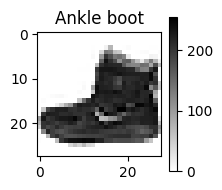

In [ ]:
# Load the Fashion MNIST dataset
fashion_mnist = keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

# Define class names for plotting
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Display the shape of the dataset
print(f"Training images shape: {train_images.shape}")
print(f"Training labels shape: {train_labels.shape}")
print(f"Test images shape: {test_images.shape}")
print(f"Test labels shape: {test_labels.shape}")

# Display a sample image
plt.figure(figsize=(2,2))
plt.imshow(train_images[0], cmap=plt.cm.binary)
plt.title(class_names[train_labels[0]])
plt.colorbar()
plt.grid(False)
plt.show()

### 2. Preprocess the Data

We need to normalize the pixel values from [0, 255] to [0, 1] to ensure that the neural network can process them effectively. This step is crucial for stable and efficient training.

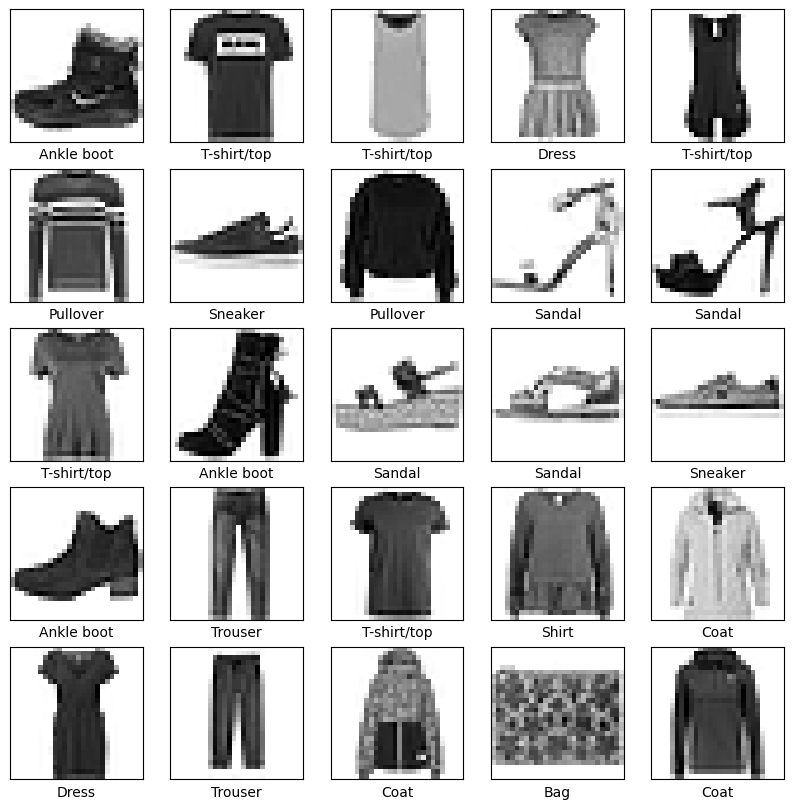

In [ ]:
# Normalize pixel values to be between 0 and 1
train_images = train_images / 255.0
test_images = test_images / 255.0

# Verify the preprocessing by displaying the first 25 images from the training set
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[train_labels[i]])
plt.show()

### 3. Build the Model Architecture

We will construct a simple feedforward neural network with three layers:
1.  **Flatten layer**: Transforms the 2D image data (28x28 pixels) into a 1D array (784 pixels).
2.  **Dense hidden layer**: A fully connected layer with 128 neurons and a ReLU activation function.
3.  **Dense output layer**: A fully connected layer with 10 neurons (one for each class) and a **softmax** activation function. Softmax converts raw scores into probabilities, where the sum of all probabilities for a given input is 1.

In [ ]:
# Build the model
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)), # Input layer - flattens 2D images to 1D arrays
    keras.layers.Dense(128, activation='relu'), # Hidden layer with 128 neurons and ReLU activation
    keras.layers.Dense(10, activation='softmax') # Output layer with 10 neurons (for 10 classes) and softmax activation
])

# Display the model summary
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### 4. Compile the Model

Before training, we need to compile the model. This involves specifying:
*   **Optimizer**: How the model updates its weights based on the loss function (e.g., 'adam').
*   **Loss Function**: Measures how well the model is performing (e.g., `sparse_categorical_crossentropy` is suitable for integer labels when the output layer is softmax).
*   **Metrics**: Used to monitor the training and testing steps (e.g., 'accuracy').

In [ ]:
# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

### 5. Train the Model

Training the model involves feeding the training data through the network for a specified number of `epochs`. The model adjusts its internal parameters to minimize the loss function.

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8175 - loss: 0.5192 - val_accuracy: 0.8567 - val_loss: 0.4144
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8617 - loss: 0.3883 - val_accuracy: 0.8601 - val_loss: 0.3833
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8723 - loss: 0.3486 - val_accuracy: 0.8698 - val_loss: 0.3567
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8825 - loss: 0.3204 - val_accuracy: 0.8770 - val_loss: 0.3415
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8873 - loss: 0.3029 - val_accuracy: 0.8784 - val_loss: 0.3414
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8946 - loss: 0.2857 - val_accuracy: 0.8752 - val_loss: 0.3434
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8979 - loss: 0.2731 - val_accuracy: 0.8820 - val_loss: 0.3232
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9012 - loss: 0.2615 -

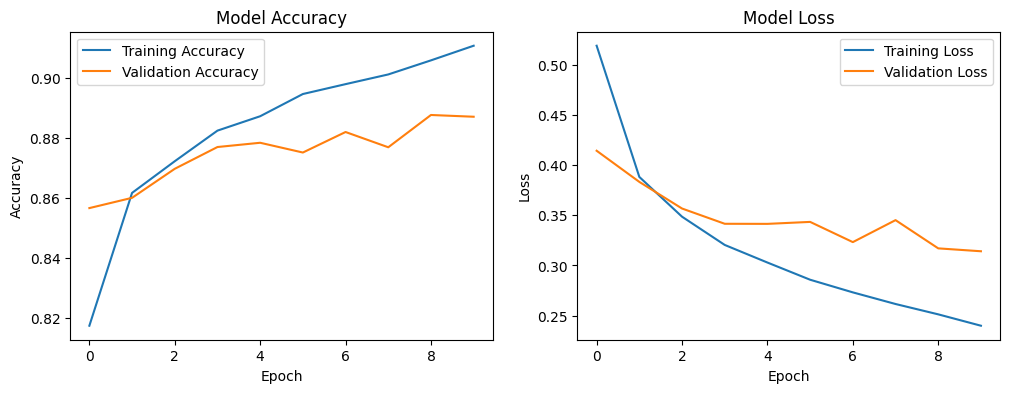

In [ ]:
# Train the model
history = model.fit(train_images, train_labels, epochs=10, validation_split=0.2)

# Plot training history (accuracy and loss)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

### 6. Evaluate the Model

After training, we evaluate the model's performance on the unseen `test_images` to check its generalization capabilities.

In [ ]:
# Evaluate the model on the test data
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f'\nTest accuracy: {test_acc}')

313/313 - 1s - 3ms/step - accuracy: 0.8795 - loss: 0.3365

Test accuracy: 0.8794999718666077


### 7. Make Predictions

Now we can use the trained model to make predictions on new images.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predictions for the first test image: [7.5544127e-10 4.6930888e-12 5.5066653e-08 2.5392177e-08 2.1651487e-09
 3.0884796e-04 3.1610785e-08 2.8273077e-03 1.2432081e-08 9.9686372e-01]
Predicted class for the first test image: 9 (Ankle boot)
True label for the first test image: 9 (Ankle boot)


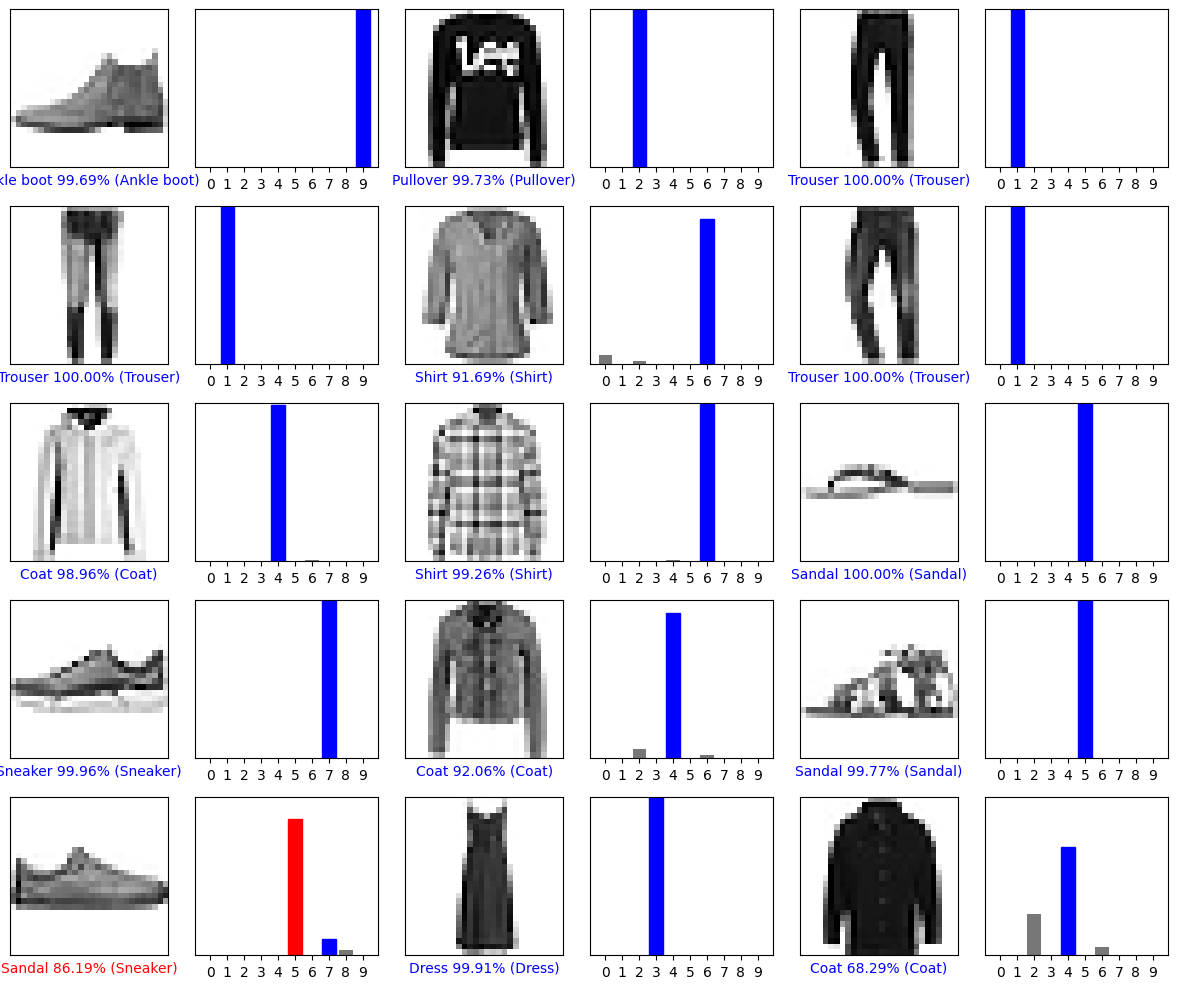

In [ ]:
# Make predictions on the test set
predictions = model.predict(test_images)

# Display the prediction for the first image
print(f"Predictions for the first test image: {predictions[0]}")
print(f"Predicted class for the first test image: {np.argmax(predictions[0])} ({class_names[np.argmax(predictions[0])]})")
print(f"True label for the first test image: {test_labels[0]} ({class_names[test_labels[0]]})")

# Function to plot image, true label, and predicted label
def plot_image_prediction(i, predictions_array, true_label, img):
  predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.imshow(img, cmap=plt.cm.binary)

  predicted_label = np.argmax(predictions_array)
  color = 'blue' if predicted_label == true_label else 'red'

  plt.xlabel(f"{class_names[predicted_label]} {100*np.max(predictions_array):.2f}% ({class_names[true_label]})", color=color)

def plot_value_array(i, predictions_array, true_label):
  predictions_array, true_label = predictions_array[i], true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

# Plot the first X test images, their predicted labels, and the true labels.
# Color correct predictions in blue, incorrect predictions in red.
num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image_prediction(i, predictions, test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, predictions, test_labels)
plt.tight_layout()
plt.show()